# Derin Öğrenme Ödev 1 - MNIST ile MLP

İsa Mirza Sincap - 23120205033

Keras ile bir MLP kurup MNIST üzerinde eğittim, birkaç hiperparametreyi değiştirip sonuçları karşılaştırdım. En sonda kendi el yazımla yazdığım okul numaramı modele verdim.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from PIL import Image, ImageOps
from scipy import ndimage
from skimage import filters, morphology, segmentation

ogrenci_no = "23120205033"
EPOCH = 15
print(tf.__version__)

2.21.0


## Veri

MNIST'in 60000'lik train setini %80 train, %20 validation olarak ayırdım. stratify kullandım ki her rakamdan iki tarafa da aynı oranda düşsün. 10000'lik test setine en sona kadar dokunmuyorum.

Pikselleri 255'e bölüp 0-1 arasına normalize ettim. MLP düz vektör aldığı için 28x28 resimleri 784'lük vektöre çevirdim.

In [2]:
(x_train_tum, y_train_tum), (x_test, y_test) = keras.datasets.mnist.load_data()

# normalizasyon + düzleştirme
x_train_tum = x_train_tum.reshape(-1, 784).astype("float32") / 255
x_test = x_test.reshape(-1, 784).astype("float32") / 255

x_train, x_val, y_train, y_val = train_test_split(
    x_train_tum, y_train_tum, test_size=0.2, stratify=y_train_tum, random_state=33)

print("train:", x_train.shape)
print("validation:", x_val.shape)
print("test:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
train: (48000, 784)
validation: (12000, 784)
test: (10000, 784)


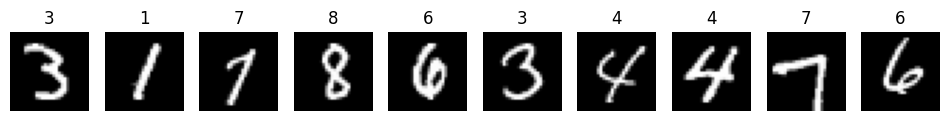

In [3]:
plt.figure(figsize=(12, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")
plt.show()

## Deney 1 - Temel MLP

Kullandığım hiperparametreler:
- 2 gizli katman: 128 ve 64 nöron, aktivasyon ReLU
- çıkış katmanı: 10 nöron, softmax
- loss: sparse categorical crossentropy (etiketler 0-9 arası sayı olduğu için)
- optimizer: Adam, learning rate 0.001
- batch size: 64
- epoch: 15
- seed: 33

In [4]:
def model_olustur(katmanlar=[128, 64], aktivasyon="relu", optimizer="adam", lr=0.001):
    keras.utils.set_random_seed(33)  # her denemede aynı seed
    model = keras.Sequential()
    model.add(keras.Input(shape=(784,)))
    for n in katmanlar:
        model.add(keras.layers.Dense(n, activation=aktivasyon))
    model.add(keras.layers.Dense(10, activation="softmax"))

    if optimizer == "adam":
        opt = keras.optimizers.Adam(learning_rate=lr)
    else:
        opt = keras.optimizers.SGD(learning_rate=lr)
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def egit(model, batch_size=64, verbose=0):
    baslangic = time.time()
    history = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                        epochs=EPOCH, batch_size=batch_size, verbose=verbose)
    sure = time.time() - baslangic
    return history.history, sure

In [5]:
model = model_olustur()
model.summary()
h, sure = egit(model, verbose=2)

print("Training loss:", round(h["loss"][-1], 4))
print("Validation loss:", round(h["val_loss"][-1], 4))
print("Training accuracy:", round(h["accuracy"][-1], 4))
print("Validation accuracy:", round(h["val_accuracy"][-1], 4))
print("Eğitim süresi:", round(sure, 1), "sn")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
750/750 - 6s - 8ms/step - accuracy: 0.9135 - loss: 0.3045 - val_accuracy: 0.9537 - val_loss: 0.1557
Epoch 2/15
750/750 - 3s - 5ms/step - accuracy: 0.9617 - loss: 0.1284 - val_accuracy: 0.9674 - val_loss: 0.1116
Epoch 3/15
750/750 - 3s - 4ms/step - accuracy: 0.9740 - loss: 0.0870 - val_accuracy: 0.9711 - val_loss: 0.0998
Epoch 4/15
750/750 - 4s - 5ms/step - accuracy: 0.9800 - loss: 0.0641 - val_accuracy: 0.9704 - val_loss: 0.0979
Epoch 5/15
750/750 - 4s - 6ms/step - accuracy: 0.9856 - loss: 0.0472 - val_accuracy: 0.9702 - val_loss: 0.1040
Epoch 6/15
750/750 - 4s - 5ms/step - accuracy: 0.9887 - loss: 0.0364 - val_accuracy: 0.9681 - val_loss: 0.1132
Epoch 7/15
750/750 - 3s - 5ms/step - accuracy: 0.9920 - loss: 0.0275 - val_accuracy: 0.9715 - val_loss: 0.1104
Epoch 8/15
750/750 - 6s - 7ms/step - accuracy: 0.9929 - loss: 0.0237 - val_accuracy: 0.9657 - val_loss: 0.1366
Epoch 9/15
750/750 - 3s - 5ms/step - accuracy: 0.9933 - loss: 0.0212 - val_accuracy: 0.9712 - val_loss: 0.1174
E

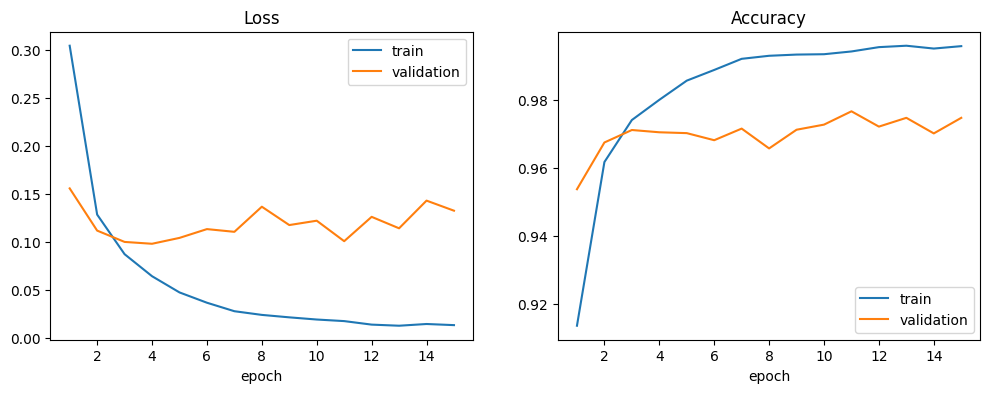

In [6]:
epochlar = range(1, EPOCH + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochlar, h["loss"], label="train")
plt.plot(epochlar, h["val_loss"], label="validation")
plt.title("Loss")
plt.xlabel("epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochlar, h["accuracy"], label="train")
plt.plot(epochlar, h["val_accuracy"], label="validation")
plt.title("Accuracy")
plt.xlabel("epoch")
plt.legend()
plt.show()

Test accuracy'yi aşağıda test kısmında hesapladım çünkü test setini model seçimi bittikten sonra kullanmak istedim.

## Hiperparametre denemeleri

Temel modelde her seferinde sadece bir şeyi değiştirdim:
- 3 gizli katman (256-128-64)
- batch size 256
- ReLU yerine sigmoid
- Adam yerine SGD (lr 0.01)
- Adam ama lr 0.01

En iyi modeli son epoch'taki validation accuracy'ye göre seçtim.

In [7]:
sonuclar = {"temel": (model, h, sure)}

denemeler = [
    # ad, katmanlar, aktivasyon, optimizer, lr, batch size
    ("3 gizli katman", [256, 128, 64], "relu", "adam", 0.001, 64),
    ("batch 256", [128, 64], "relu", "adam", 0.001, 256),
    ("sigmoid", [128, 64], "sigmoid", "adam", 0.001, 64),
    ("sgd lr=0.01", [128, 64], "relu", "sgd", 0.01, 64),
    ("adam lr=0.01", [128, 64], "relu", "adam", 0.01, 64),
]

for ad, katmanlar, akt, opt, lr, bs in denemeler:
    m = model_olustur(katmanlar, akt, opt, lr)
    hh, s = egit(m, batch_size=bs)
    sonuclar[ad] = (m, hh, s)
    print(ad, "bitti")

3 gizli katman bitti
batch 256 bitti
sigmoid bitti
sgd lr=0.01 bitti
adam lr=0.01 bitti


deneme           train loss  val loss  train acc  val acc    süre
temel                0.0130    0.1324     0.9958   0.9747   61.0s
3 gizli katman       0.0151    0.1083     0.9948   0.9770   99.0s
batch 256            0.0163    0.1059     0.9966   0.9715   31.3s
sigmoid              0.0171    0.0834     0.9972   0.9757   64.5s
sgd lr=0.01          0.1538    0.1604     0.9559   0.9522   49.6s
adam lr=0.01         0.0711    0.1908     0.9826   0.9683   59.3s


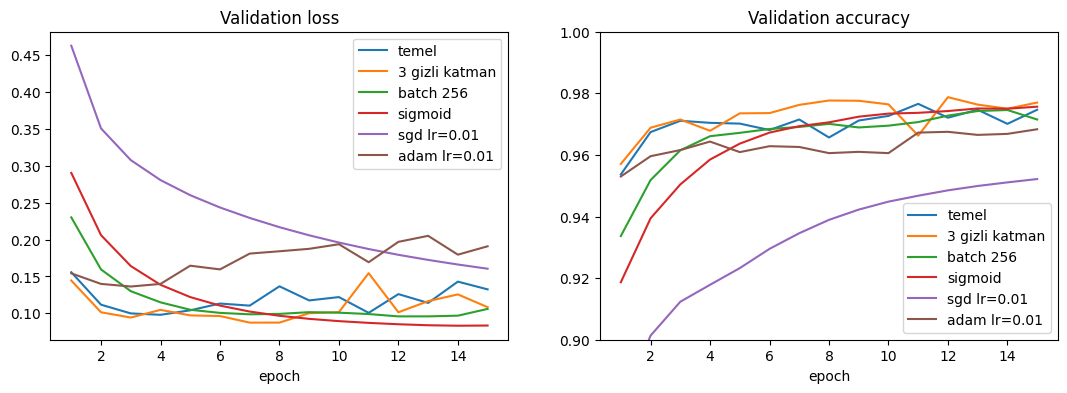

validation'a göre en iyi model: 3 gizli katman


In [8]:
print(f"{'deneme':<16}{'train loss':>11}{'val loss':>10}{'train acc':>11}{'val acc':>9}{'süre':>8}")
for ad, (m, hh, s) in sonuclar.items():
    print(f"{ad:<16}{hh['loss'][-1]:>11.4f}{hh['val_loss'][-1]:>10.4f}"
          f"{hh['accuracy'][-1]:>11.4f}{hh['val_accuracy'][-1]:>9.4f}{s:>7.1f}s")

plt.figure(figsize=(13, 4))
for ad, (m, hh, s) in sonuclar.items():
    plt.subplot(1, 2, 1)
    plt.plot(epochlar, hh["val_loss"], label=ad)
    plt.subplot(1, 2, 2)
    plt.plot(epochlar, hh["val_accuracy"], label=ad)
plt.subplot(1, 2, 1)
plt.title("Validation loss")
plt.xlabel("epoch")
plt.legend()
plt.subplot(1, 2, 2)
plt.title("Validation accuracy")
plt.xlabel("epoch")
plt.ylim(0.9, 1)
plt.legend()
plt.show()

en_iyi = max(sonuclar, key=lambda ad: sonuclar[ad][1]["val_accuracy"][-1])
en_iyi_model = sonuclar[en_iyi][0]
print("validation'a göre en iyi model:", en_iyi)

## Test

Test setini sadece burada, seçimleri yaptıktan sonra kullandım.

Deney 1 (temel model) test accuracy: 0.9742
3 gizli katman test accuracy: 0.9781


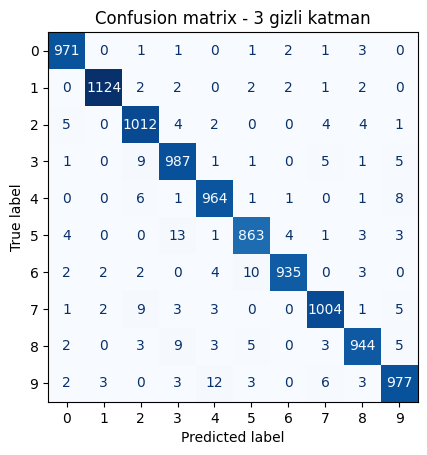

In [9]:
_, test_acc = model.evaluate(x_test, y_test, verbose=0)
print("Deney 1 (temel model) test accuracy:", round(test_acc, 4))

_, test_acc_en_iyi = en_iyi_model.evaluate(x_test, y_test, verbose=0)
print(en_iyi, "test accuracy:", round(test_acc_en_iyi, 4))

tahmin = en_iyi_model.predict(x_test, verbose=0).argmax(axis=1)
ConfusionMatrixDisplay(confusion_matrix(y_test, tahmin)).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix - " + en_iyi)
plt.show()

## Kendi el yazım

Beyaz kağıda okul numaramı yazıp fotoğrafını çektim ve Colab'da dosyalar kısmına "numara.jpg" olarak yükledim.

Fotoğrafı MNIST'e benzetmek için yaptıklarım:
- gri tona çevirdim
- renkleri ters çevirdim (MNIST'te arka plan siyah, rakam beyaz)
- eşikleme yapıp rakamları arka plandan ayırdım
- boş sütunlara bakarak rakamları tek tek kestim
- çizgi kalınlığını MNIST'tekine yakın olacak şekilde ayarladım
- her rakamı 20x20'ye sığdırıp 28x28'lik resmin ortasına koydum (MNIST de böyle hazırlanmış)
- 0-1 arasına normalize ettim

Karşılaştırma için aynı rakamları bir de direkt 28x28'e küçültüp modele verdim.

11 rakam bulundu


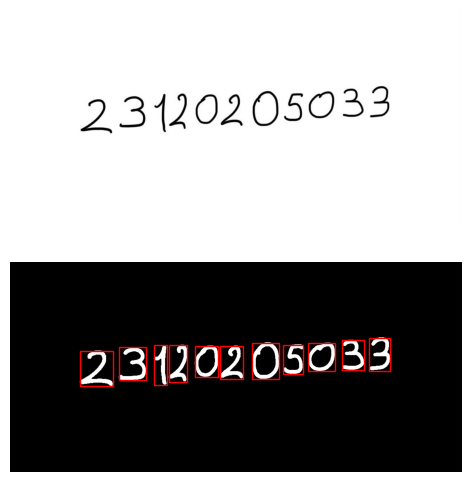

In [10]:
gorsel_yolu = "numara.jpg"

img = Image.open(gorsel_yolu)
img = ImageOps.exif_transpose(img)  # telefon fotoğrafı yan dönmesin
img = img.convert("L")              # gri ton
img.thumbnail((1200, 1200))
a = np.array(img, dtype="float32")
a = 255 - a                         # ters çevir
a = ndimage.gaussian_filter(a, 2)

# gölgeli fotoğrafta da çalışsın diye yerel eşik
maske = a > filters.threshold_local(a, 151, offset=-12)
maske = segmentation.clear_border(maske)  # kenara değen lekeler

# küçük lekeleri sil
etiket, _ = ndimage.label(maske)
alanlar = np.bincount(etiket.ravel())
alanlar[0] = 0
maske = alanlar[etiket] >= 0.03 * alanlar.max()

# hiç beyaz piksel olmayan sütunlar rakamların arasındaki boşluk
sutun_dolu = maske.any(axis=0)
kutular = []
x = 0
while x < len(sutun_dolu):
    if sutun_dolu[x]:
        bas = x
        while x < len(sutun_dolu) and sutun_dolu[x]:
            x += 1
        satirlar = np.where(maske[:, bas:x].any(axis=1))[0]
        kutular.append((satirlar[0], satirlar[-1] + 1, bas, x))
    x += 1

# çok kısa kalanlar leke
en_uzun = max(k[1] - k[0] for k in kutular)
kutular = [k for k in kutular if k[1] - k[0] > 0.4 * en_uzun]
print(len(kutular), "rakam bulundu")

plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.subplot(2, 1, 2)
plt.imshow(maske, cmap="gray")
for y0, y1, x0, x1 in kutular:
    plt.gca().add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="red"))
plt.axis("off")
plt.show()

In [11]:
def mnist_formatina_cevir(rakam):
    # çizgiyi önce inceltip sonra rakamın boyuna göre kalınlaştırıyorum
    r = max(1, round(0.06 * max(rakam.shape)))
    rakam = np.pad(rakam, r)
    rakam = morphology.skeletonize(rakam)
    rakam = ndimage.binary_dilation(rakam, structure=morphology.disk(r))

    # oranı bozmadan 20x20'ye sığdır
    h, w = rakam.shape
    oran = 20 / max(h, w)
    yeni_w = max(1, round(w * oran))
    yeni_h = max(1, round(h * oran))
    kucuk = Image.fromarray(rakam.astype(np.uint8) * 255).resize((yeni_w, yeni_h), Image.LANCZOS)

    # 28x28 siyah resmin ortasına koy
    sonuc = np.zeros((28, 28), dtype="float32")
    y0 = (28 - yeni_h) // 2
    x0 = (28 - yeni_w) // 2
    sonuc[y0:y0 + yeni_h, x0:x0 + yeni_w] = np.array(kucuk) / 255

    # kütle merkezini ortaya kaydır
    cy, cx = ndimage.center_of_mass(sonuc)
    sonuc = ndimage.shift(sonuc, (14 - cy, 14 - cx))
    return np.clip(sonuc, 0, 1)


def direkt_kucult(rakam):
    kucuk = Image.fromarray(rakam.astype(np.uint8) * 255).resize((28, 28))
    return np.array(kucuk, dtype="float32") / 255

direkt küçültme
  tahmin: 26955213536
  gerçek: 23120205033
  doğru: 3 / 11


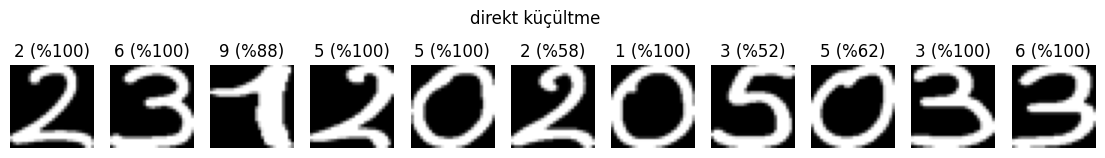

MNIST formatı
  tahmin: 23120205033
  gerçek: 23120205033
  doğru: 11 / 11


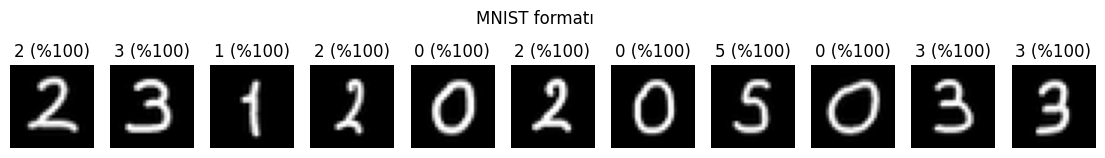

In [12]:
rakamlar = [maske[y0:y1, x0:x1] for y0, y1, x0, x1 in kutular]
X_direkt = np.array([direkt_kucult(r) for r in rakamlar])
X_mnist = np.array([mnist_formatina_cevir(r) for r in rakamlar])

for isim, X in [("direkt küçültme", X_direkt), ("MNIST formatı", X_mnist)]:
    olasilik = en_iyi_model.predict(X.reshape(-1, 784), verbose=0)
    tahmin = olasilik.argmax(axis=1)
    dogru = sum(str(t) == g for t, g in zip(tahmin, ogrenci_no))
    print(isim)
    print("  tahmin:", "".join(str(t) for t in tahmin))
    print("  gerçek:", ogrenci_no)
    print("  doğru:", dogru, "/", len(ogrenci_no))

    plt.figure(figsize=(14, 2))
    for i in range(len(X)):
        plt.subplot(1, len(X), i + 1)
        plt.imshow(X[i], cmap="gray")
        plt.title(f"{tahmin[i]} (%{olasilik[i].max() * 100:.0f})")
        plt.axis("off")
    plt.suptitle(isim)
    plt.show()

## Değerlendirme

**Deney 1 (temel model):** 15 epoch sonunda training loss 0.0130, validation loss 0.1324, training accuracy 0.9958, validation accuracy 0.9747 ve test accuracy 0.9742 oldu. Eğitim Colab CPU'da 61 saniye sürdü. Grafiğe bakınca train loss sürekli düşüyor ama validation loss en düşük değerine 4. epoch'ta ulaşıyor (0.098), sonra yavaş yavaş artıyor. Yani 4-5. epoch'tan sonra model train verisini ezberlemeye başlıyor (overfitting). Validation accuracy ise 0.97 civarında sabit kalıyor, o yüzden ezberleme accuracy'yi çok düşürmemiş ama 15 epoch gereksiz fazla.

**Hiperparametre denemeleri:**
- 3 gizli katman (256-128-64) validation accuracy'de en iyisi oldu (0.9770), testte de 0.9781 verdi. Parametre sayısı iki katından fazla olduğu için eğitim daha uzun sürdü (99 sn).
- Batch 256 en hızlısı oldu (31 sn) çünkü epoch başına daha az güncelleme yapılıyor, ama validation accuracy biraz düştü (0.9715).
- Sigmoid ile validation loss en düşük çıktı (0.0834). Sigmoid daha yavaş öğrendiği için 15 epoch'ta ReLU kadar ezberleyememiş diye düşünüyorum. Accuracy olarak ReLU ile neredeyse aynı.
- Momentumsuz SGD (lr 0.01) en kötüsü oldu (0.9522). Grafikte eğrisi hâlâ yükseliyordu, daha fazla epoch verilse yetişirdi, yani SGD burada Adam'a göre çok yavaş.
- Adam'da learning rate'i 0.01'e çıkarınca validation loss en yüksek değere çıktı (0.1908) ve eğri zikzaklı oldu. Learning rate büyük olunca adımlar fazla büyük oluyor ve model iyi bir noktaya oturamıyor.

**Test:** Seçilen modelde (3 gizli katman) test accuracy 0.9781. Confusion matrix'te en çok karışanlar 5'in 3 sanılması (13), 9'un 4 sanılması (12) ve 6'nın 5 sanılması (10). Bu rakamlar yazılışı olarak birbirine benzediği için mantıklı. MLP resmi düz vektör olarak gördüğü için şekil bilgisini CNN kadar iyi kullanamıyor.

**Kendi el yazım:** Rakamları direkt 28x28'e küçültünce model sadece 3/11 doğru bildi. Aynı rakamları MNIST'teki gibi hazırlayınca (20x20'ye sığdırma, ortalama, çizgi kalınlığını ayarlama) 11/11 doğru bildi. Direkt küçültmede rakamlar resmin tamamını kaplıyor, uzuyor ve çizgiler çok kalın oluyor. Model bunları eğitimde hiç görmediği için MNIST'te %97.8 başarılı olmasına rağmen burada neredeyse tamamen yanıldı. Buradan anladığım, modelin rakamı değil eğitim verisindeki görüntü dağılımını öğrendiği. Gerçek veri bu dağılıma benzemezse (distribution shift) başarı çok düşüyor, ön işleme ile benzetince düzeliyor. Yalnız 11 rakam az bir örnek, farklı bir yazıyla ya da kötü bir fotoğrafla sonuç düşebilir.
